In [1]:
# Import Libraries
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Dataset
df = pd.read_csv(
    r'C:\Users\sunda\OneDrive\Desktop\Python_works\job_postings_flat.csv'
)

In [2]:
# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) else []
)

In [11]:
# Filter Finland jobs and drop missing salary values 
df_fin = df[df['job_country'] == 'Finland'].dropna(subset=['salary_year_avg'])

job_titles = df_fin['job_title_short'].value_counts().index[:6].tolist()

# filter the df for the top 6 job titles
df_fin_top6 = df_fin[df_fin['job_title_short'].isin(job_titles)]

# order the job titles by median salary
job_order = df_fin_top6.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending=False).index


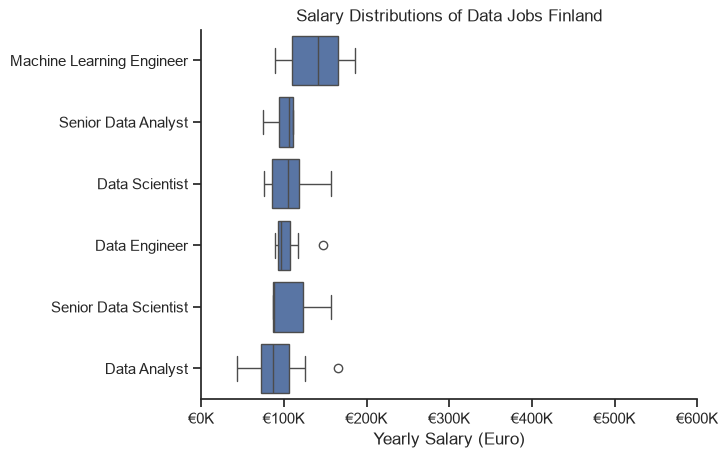

In [20]:
# plot
sns.boxplot(data=df_fin_top6, x='salary_year_avg', y='job_title_short', order=job_order)
sns.set_theme(style='ticks')
sns.despine()

# this is all the same
plt.title('Salary Distributions of Data Jobs Finland')
plt.xlabel('Yearly Salary (Euro)')
plt.ylabel('')
plt.xlim(0, 600000) 
ticks_x = plt.FuncFormatter(lambda y, pos: f'€{int(y/1000)}K')
plt.gca().xaxis.set_major_formatter(ticks_x)
plt.show()

In [13]:
# Only get data analyst jobs in the US
df_DA_fin = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'Finland')].copy()

# Drop NaN values from the 'salary_year_avg' column for accurate visualization
df_DA_fin = df_DA_fin.dropna(subset=['salary_year_avg'])

df_DA_fin = df_DA_fin.explode('job_skills')

df_DA_fin[['salary_year_avg', 'job_skills']].head(5)

,salary_year_avg,job_skills
52072,105650.0,sql
52072,105650.0,looker
52072,105650.0,tableau
144543,165000.0,go
144543,165000.0,azure


In [14]:
# to get the highest paid skills and most demanded 
df_DA_top_pay = df_DA_fin.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by='median', ascending=False)

df_DA_top_pay = df_DA_top_pay.head(10)

df_DA_top_pay

,count,median
job_skills,,
azure,1,165000.00
go,2,145000.00
alteryx,1,125000.00
looker,2,115325.00
sql,1,105650.00
tableau,1,105650.00
linux,1,86875.00
python,2,86861.25
power bi,1,86847.50


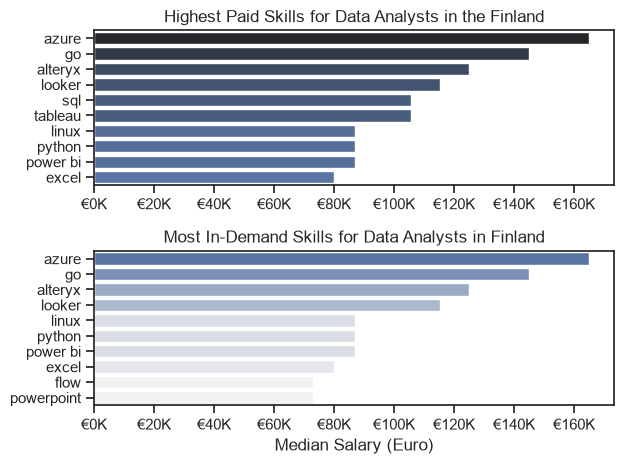

In [18]:
# count and median salary of each skill
df_DA_skills = df_DA_fin.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by='count', ascending=False)

df_DA_skills = df_DA_skills.head(10).sort_values(by='median', ascending=False)

df_DA_skills

# plot
fig, ax = plt.subplots(2, 1)  

# Top 10 Highest Paid Skills for Data Analysts
sns.barplot(data=df_DA_top_pay, x='median', y=df_DA_top_pay.index, hue='median', ax=ax[0], palette='dark:b_r')
ax[0].legend().remove()
# original code:
# df_DA_top_pay[::-1].plot(kind='barh', y='median', ax=ax[0], legend=False) 
ax[0].set_title('Highest Paid Skills for Data Analysts in the Finland')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'€{int(x/1000)}K'))


# Top 10 Most In-Demand Skills for Data Analysts')
sns.barplot(data=df_DA_skills, x='median', y=df_DA_skills.index, hue='median', ax=ax[1], palette='light:b')
ax[1].legend().remove()
# original code:
# df_DA_skills[::-1].plot(kind='barh', y='median', ax=ax[1], legend=False)
ax[1].set_title('Most In-Demand Skills for Data Analysts in Finland')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary (Euro)')
ax[1].set_xlim(ax[0].get_xlim())  # Set the same x-axis limits as the first plot
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'€{int(x/1000)}K'))

sns.set_theme(style='ticks')
plt.tight_layout()
plt.show()